## 5-7_Varying_the_Classification_Threshold_in_Logistic_Regression

In [1]:
## 1. Load the dataset and split it into training and test sets.

import pandas as pd

data_web_address = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
column_names = ['pregnancy_x', 
                'plasma_con', 
                'blood_pressure', 
                'skin_mm', 
                'insulin', 
                'bmi', 
                'pedigree_func', 
                'age', 
                'target']

feature_names = column_names[:-1]
all_data = pd.read_csv(data_web_address , names=column_names)
all_data.head()

import numpy as np
import pandas as pd

X = all_data[feature_names]
y = all_data['target']


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7,stratify=y)

In [2]:
## 2. Train the logistic regression model and predict the test labels.

from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test)

e:\ML\ML-Engineering-Lab\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [3]:
## 3. Predict class probabilities for the test data.

y_pred_proba = lr.predict_proba(X_test)

In [4]:
## 4. Display the predicted class probabilities.

y_pred_proba

array([[0.90584499, 0.09415501],
       [0.89448609, 0.10551391],
       [0.8778818 , 0.1221182 ],
       [0.82384239, 0.17615761],
       [0.82170143, 0.17829857],
       [0.99371579, 0.00628421],
       [0.94605101, 0.05394899],
       [0.72010826, 0.27989174],
       [0.91593691, 0.08406309],
       [0.43172391, 0.56827609],
       [0.81038019, 0.18961981],
       [0.3724275 , 0.6275725 ],
       [0.82763571, 0.17236429],
       [0.82707572, 0.17292428],
       [0.19547143, 0.80452857],
       [0.94847812, 0.05152188],
       [0.47725403, 0.52274597],
       [0.79225304, 0.20774696],
       [0.74418655, 0.25581345],
       [0.98248718, 0.01751282],
       [0.28260831, 0.71739169],
       [0.30763668, 0.69236332],
       [0.72325692, 0.27674308],
       [0.6910227 , 0.3089773 ],
       [0.24266826, 0.75733174],
       [0.73003187, 0.26996813],
       [0.70636843, 0.29363157],
       [0.93285639, 0.06714361],
       [0.85803306, 0.14196694],
       [0.13999243, 0.86000757],
       [0.

<Axes: >

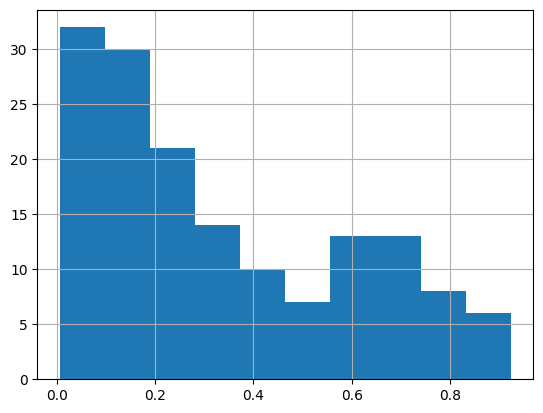

In [5]:
## 5. Visualize the distribution of predicted positive-class probabilities.

%matplotlib inline
pd.Series(y_pred_proba[:,1]).hist()

<Axes: >

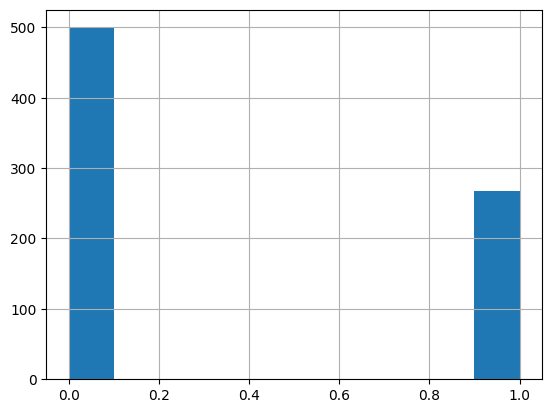

In [6]:
## 6. Visualize the distribution of actual target labels.

all_data['target'].hist()

In [7]:
## 7. Binarize predicted probabilities using the default threshold of 0.5.

from sklearn.preprocessing import binarize

y_pred_default = binarize(y_pred_proba, threshold=0.5)
y_pred_default

array([[1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.

In [8]:
## 8. Extract the predicted labels for the positive class.

y_pred_default[:,1]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 1., 0., 1.,
       0., 0., 0., 1., 1., 0., 0., 1., 0., 0., 0., 0., 1., 1., 1., 0., 0.,
       1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
       1., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 1.,
       0., 1., 1., 0., 0., 1., 0., 1., 1., 0., 0., 0., 1., 1., 0., 0., 0.,
       0., 1., 0., 1., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 1., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0.,
       0., 1., 0., 1., 1., 0., 0., 0., 1., 1., 0., 0., 0., 1., 0., 0., 1.,
       0., 0., 1., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.,
       1.])

In [9]:
## 9. Evaluate predictions at the default threshold using a confusion matrix.

from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred_default[:,1],labels = [1,0])

array([[33, 21],
       [12, 88]])

In [10]:
## 10. Lower the classification threshold to 0.2 and examine the confusion matrix.

y_pred_low = binarize(y_pred_proba, threshold=0.2)
confusion_matrix(y_test, y_pred_low[:,1],labels=[1,0]) #positive class is 1 again

array([[47,  7],
       [42, 58]])

In [11]:
## 11. Define a function to calculate negative predictive value.

from __future__ import division 
def npv_func(th):
    y_pred_low = binarize(y_pred_proba, threshold=th)

    second_column = confusion_matrix(y_test, y_pred_low[:,1],labels=[1,0])[:,1]
    npv = second_column[1]/second_column.sum()
    return npv

npv_func(0.2)

np.float64(0.8923076923076924)

C:\Users\toshi\AppData\Local\Temp\ipykernel_17480\1122588036.py:8: RuntimeWarning: invalid value encountered in scalar divide
  npv = second_column[1]/second_column.sum()


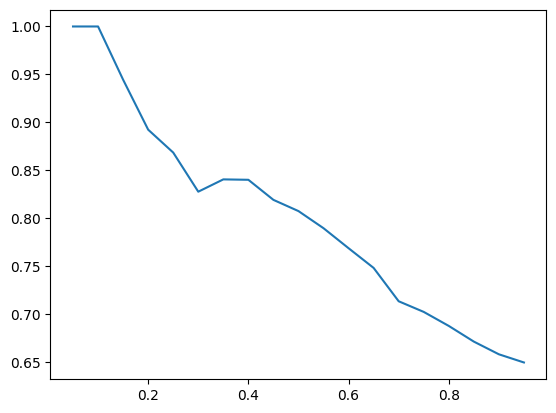

In [12]:
## 12. Plot negative predictive value across classification thresholds.

import matplotlib.pyplot as plt
ths = np.arange(0,1,0.05)

npvs = []
for th in np.arange(0,1.00,0.05):
    npvs.append(npv_func(th)) 

plt.plot(ths,npvs)